In [7]:
!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels plotly openpyxl

In [20]:
from google.colab import files
uploaded = files.upload()

Saving Retail_Sales_Data.csv to Retail_Sales_Data.csv


In [21]:
import pandas as pd
df = pd.read_csv("Retail_Sales_Data.csv")
print("Dataset loaded successfully!")
print(df.shape)
display(df.head())

Dataset loaded successfully!
(73000, 19)


,Date,Store_ID,Store_Location,Product_ID,Product_Category,Product_Subcategory,Brand,Unit_Price,Units_Sold,Total_Sales,Discount_Percentage,Revenue,Customer_Type,Payment_Mode,Promotion_Applied,Stock_On_Hand,Store_Rating,Region,Holiday_Flag
0,13-04-2023,STR_104,Chennai,PRD_072,Sports,Athletics,Reebok,29973.06,39,1168949.34,5,1.110502e+06,Returning,Debit Card,Yes,422,4.4,South,0
1,25-10-2024,STR_103,Delhi,PRD_492,Sports,Outdoor,Yonex,46933.78,2,93867.56,15,7.978743e+04,Returning,UPI,No,302,4.1,North,0
2,28-02-2023,STR_107,Kolkata,PRD_958,Groceries,Household,Nestle,39280.28,44,1728332.32,15,1.469082e+06,Returning,Cash,No,184,3.8,East,0
3,16-06-2023,STR_102,Bangalore,PRD_014,Home Appliances,Kitchen,Whirlpool,40439.03,9,363951.27,5,3.457537e+05,New,UPI,Yes,493,3.7,South,0
4,23-05-2024,STR_108,Ahmedabad,PRD_932,Fashion,Women Clothing,Puma,9193.58,4,36774.32,5,3.493560e+04,Returning,Credit Card,No,359,3.5,West,0


In [22]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73000 entries, 0 to 72999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date                 73000 non-null  object 
 1   Store_ID             73000 non-null  object 
 2   Store_Location       73000 non-null  object 
 3   Product_ID           73000 non-null  object 
 4   Product_Category     73000 non-null  object 
 5   Product_Subcategory  73000 non-null  object 
 6   Brand                73000 non-null  object 
 7   Unit_Price           73000 non-null  float64
 8   Units_Sold           73000 non-null  int64  
 9   Total_Sales          73000 non-null  float64
 10  Discount_Percentage  73000 non-null  int64  
 11  Revenue              73000 non-null  float64
 12  Customer_Type        73000 non-null  object 
 13  Payment_Mode         73000 non-null  object 
 14  Promotion_Applied    73000 non-null  object 
 15  Stock_On_Hand  

In [23]:
print("Missing values in each column:")
print(df.isnull().sum())
print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
Date                   0
Store_ID               0
Store_Location         0
Product_ID             0
Product_Category       0
Product_Subcategory    0
Brand                  0
Unit_Price             0
Units_Sold             0
Total_Sales            0
Discount_Percentage    0
Revenue                0
Customer_Type          0
Payment_Mode           0
Promotion_Applied      0
Stock_On_Hand          0
Store_Rating           0
Region                 0
Holiday_Flag           0
dtype: int64

Total missing values:
0


In [24]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [25]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
df = df.drop_duplicates()
df = df.dropna(subset=["Date"])
print("Cleaned dataset shape:", df.shape)
display(df.head())

Cleaned dataset shape: (44357, 19)


,Date,Store_ID,Store_Location,Product_ID,Product_Category,Product_Subcategory,Brand,Unit_Price,Units_Sold,Total_Sales,Discount_Percentage,Revenue,Customer_Type,Payment_Mode,Promotion_Applied,Stock_On_Hand,Store_Rating,Region,Holiday_Flag
0,2023-04-13,STR_104,Chennai,PRD_072,Sports,Athletics,Reebok,29973.06,39,1168949.34,5,1.110502e+06,Returning,Debit Card,Yes,422,4.4,South,0
1,2024-10-25,STR_103,Delhi,PRD_492,Sports,Outdoor,Yonex,46933.78,2,93867.56,15,7.978743e+04,Returning,UPI,No,302,4.1,North,0
2,2023-02-28,STR_107,Kolkata,PRD_958,Groceries,Household,Nestle,39280.28,44,1728332.32,15,1.469082e+06,Returning,Cash,No,184,3.8,East,0
3,2023-06-16,STR_102,Bangalore,PRD_014,Home Appliances,Kitchen,Whirlpool,40439.03,9,363951.27,5,3.457537e+05,New,UPI,Yes,493,3.7,South,0
4,2024-05-23,STR_108,Ahmedabad,PRD_932,Fashion,Women Clothing,Puma,9193.58,4,36774.32,5,3.493560e+04,Returning,Credit Card,No,359,3.5,West,0


In [26]:
total_revenue = df["Revenue"].sum()
total_sales = df["Total_Sales"].sum()
total_units = df["Units_Sold"].sum()
total_stores = df["Store_ID"].nunique()
total_categories = df["Product_Category"].nunique()
print("TOTAL REVENUE:", round(total_revenue, 2))
print("TOTAL SALES:", round(total_sales, 2))
print("TOTAL UNITS SOLD:", total_units)
print("TOTAL STORES:", total_stores)
print("TOTAL PRODUCT CATEGORIES:", total_categories)

TOTAL REVENUE: 25116474174.9
TOTAL SALES: 27918688998.09
TOTAL UNITS SOLD: 1109001
TOTAL STORES: 8
TOTAL PRODUCT CATEGORIES: 5


In [28]:
print("Dataset shape:", df.shape)
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())

Dataset shape: (44357, 19)
First date: 2023-01-13 00:00:00
Last date: 2024-12-31 00:00:00
Missing values: 0
Duplicate records: 0


Date
2023-01    1.146864e+09
2023-02    9.121254e+08
2023-03    1.064206e+09
2023-04    1.024655e+09
2023-05    1.055429e+09
2023-06    1.001235e+09
2023-07    1.078665e+09
2023-08    1.103775e+09
2023-09    1.032008e+09
2023-10    1.093657e+09
2023-11    1.024221e+09
2023-12    1.081015e+09
2024-01    1.070428e+09
2024-02    9.325708e+08
2024-03    1.078216e+09
2024-04    9.842205e+08
2024-05    1.045812e+09
2024-06    1.048194e+09
2024-07    1.073757e+09
2024-08    1.110385e+09
2024-09    1.007445e+09
2024-10    1.063121e+09
2024-11    1.011221e+09
2024-12    1.073248e+09
Name: Revenue, dtype: float64


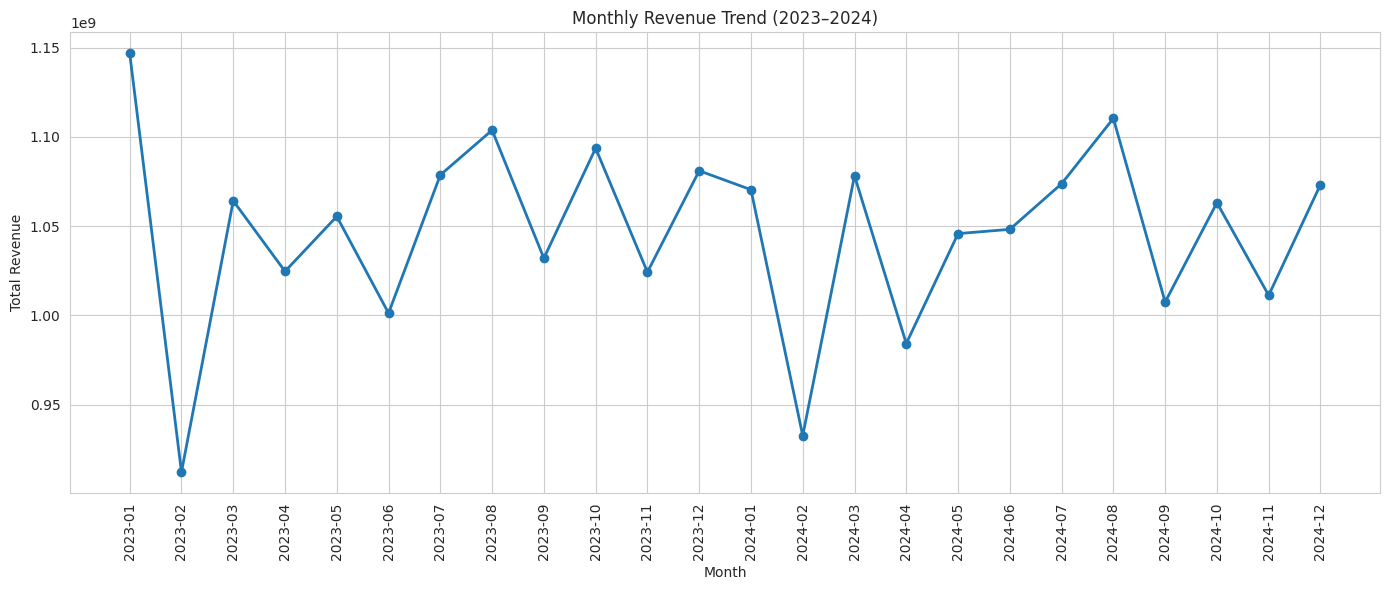

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
monthly_revenue = df.groupby(
    df["Date"].dt.to_period("M")
)["Revenue"].sum()
monthly_revenue.index = monthly_revenue.index.astype(str)
print(monthly_revenue)
plt.figure(figsize=(14, 6))
plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o",
    linewidth=2
)
plt.title("Monthly Revenue Trend (2023–2024)")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

Product_Category
Electronics        5.089302e+09
Home Appliances    5.068542e+09
Groceries          5.027088e+09
Fashion            4.986689e+09
Sports             4.944852e+09
Name: Revenue, dtype: float64


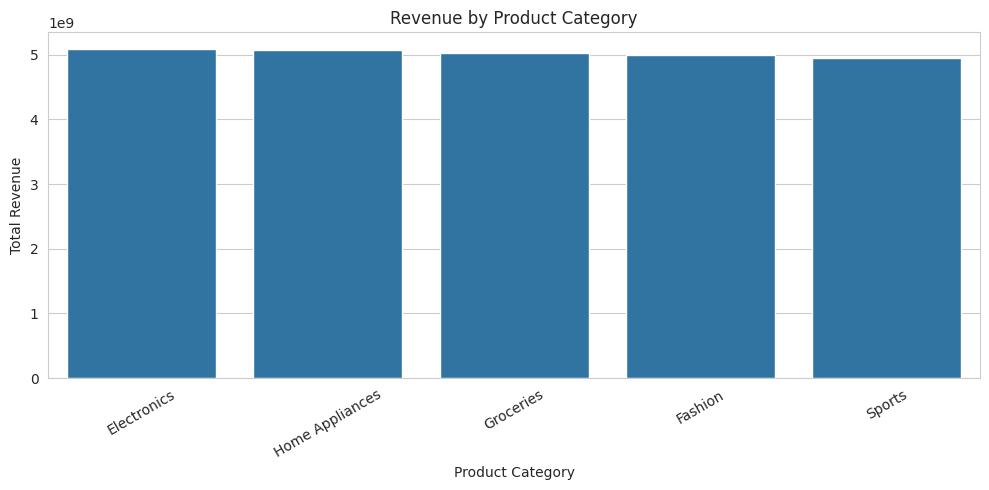

In [30]:
category_revenue = df.groupby(
    "Product_Category"
)["Revenue"].sum().sort_values(ascending=False)
print(category_revenue)
plt.figure(figsize=(10, 5))
sns.barplot(
    x=category_revenue.index,
    y=category_revenue.values
)
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Store_Location
Delhi        3.243379e+09
Kolkata      3.186874e+09
Pune         3.152386e+09
Bangalore    3.146458e+09
Chennai      3.145558e+09
Mumbai       3.128283e+09
Ahmedabad    3.078556e+09
Hyderabad    3.034981e+09
Name: Revenue, dtype: float64


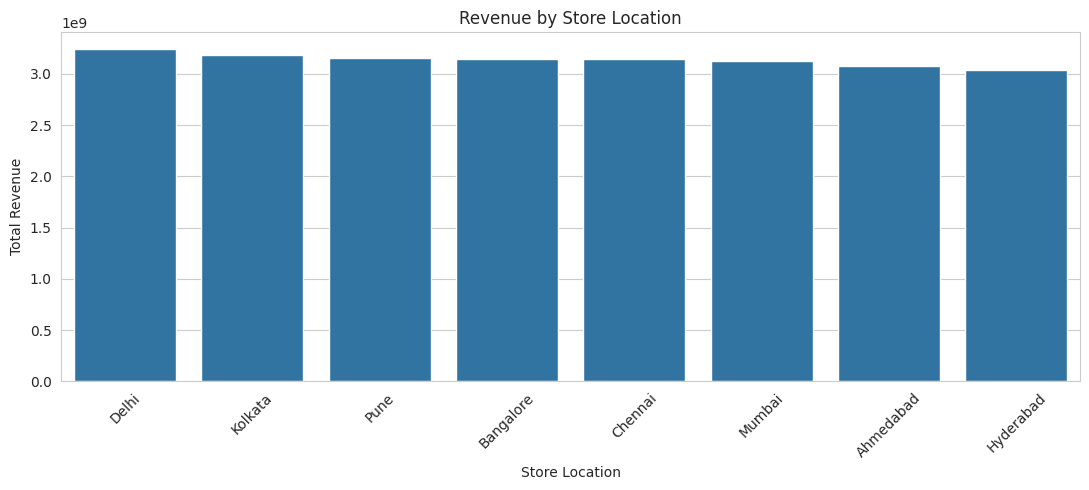

In [31]:
store_revenue = df.groupby(
    "Store_Location"
)["Revenue"].sum().sort_values(ascending=False)
print(store_revenue)
plt.figure(figsize=(11, 5))
sns.barplot(
    x=store_revenue.index,
    y=store_revenue.values
)
plt.title("Revenue by Store Location")
plt.xlabel("Store Location")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10
print("Visualization libraries ready!")

Visualization libraries ready!


In [34]:
import pandas as pd
import numpy as np
monthly_sales = (
    df.set_index("Date")["Revenue"]
    .resample("MS")
    .sum()
)
print("Monthly sales data:")
print(monthly_sales)
print("\nTotal months:", len(monthly_sales))

Monthly sales data:
Date
2023-01-01    1.146864e+09
2023-02-01    9.121254e+08
2023-03-01    1.064206e+09
2023-04-01    1.024655e+09
2023-05-01    1.055429e+09
2023-06-01    1.001235e+09
2023-07-01    1.078665e+09
2023-08-01    1.103775e+09
2023-09-01    1.032008e+09
2023-10-01    1.093657e+09
2023-11-01    1.024221e+09
2023-12-01    1.081015e+09
2024-01-01    1.070428e+09
2024-02-01    9.325708e+08
2024-03-01    1.078216e+09
2024-04-01    9.842205e+08
2024-05-01    1.045812e+09
2024-06-01    1.048194e+09
2024-07-01    1.073757e+09
2024-08-01    1.110385e+09
2024-09-01    1.007445e+09
2024-10-01    1.063121e+09
2024-11-01    1.011221e+09
2024-12-01    1.073248e+09
Freq: MS, Name: Revenue, dtype: float64

Total months: 24


In [35]:
train = monthly_sales.iloc[:-6]
test = monthly_sales.iloc[-6:]
print("Training records:", len(train))
print("Testing records:", len(test))
print("\nTraining period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training records: 18
Testing records: 6

Training period: 2023-01-01 00:00:00 to 2024-06-01 00:00:00
Testing period: 2024-07-01 00:00:00 to 2024-12-01 00:00:00


In [36]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
model = ExponentialSmoothing(
    train,
    trend="add",
    damped_trend=True,
    initialization_method="estimated"
)
fitted_model = model.fit(optimized=True)
predictions = fitted_model.forecast(6)
print("Predicted revenue for testing period:")
print(predictions)

Predicted revenue for testing period:
2024-07-01    1.046474e+09
2024-08-01    1.046520e+09
2024-09-01    1.046557e+09
2024-10-01    1.046587e+09
2024-11-01    1.046611e+09
2024-12-01    1.046630e+09
Freq: MS, dtype: float64


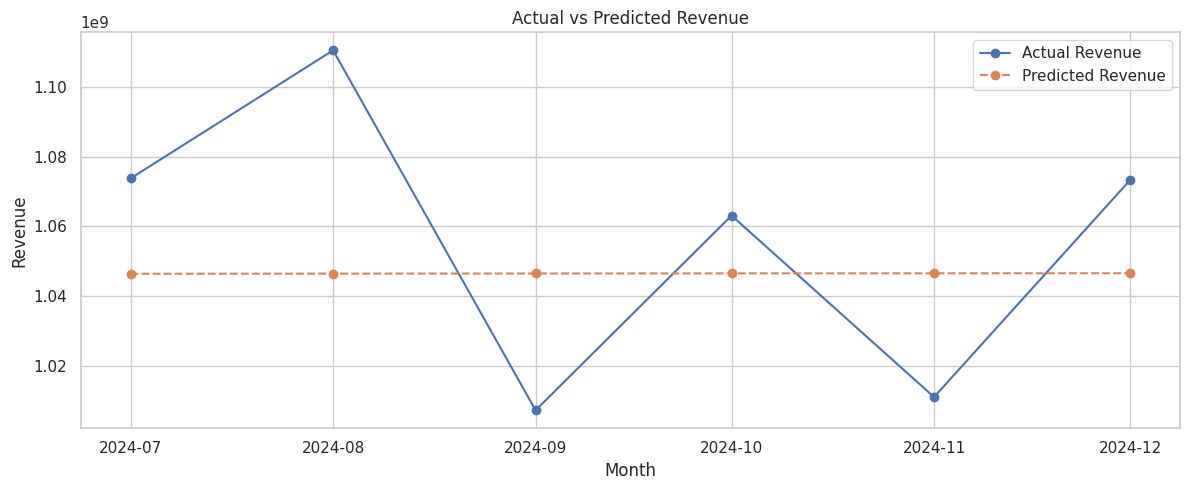

In [37]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.plot(test.index, test.values,
         marker="o", label="Actual Revenue")
plt.plot(predictions.index, predictions.values,
         marker="o", linestyle="--",
         label="Predicted Revenue")
plt.title("Actual vs Predicted Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [38]:
final_model = ExponentialSmoothing(
    monthly_sales,
    trend="add",
    damped_trend=True,
    initialization_method="estimated"
).fit(optimized=True)
future_forecast = final_model.forecast(6)
print("NEXT 6 MONTHS REVENUE FORECAST")
print("--------------------------------")
print(future_forecast)

NEXT 6 MONTHS REVENUE FORECAST
--------------------------------
2025-01-01    1.049041e+09
2025-02-01    1.049053e+09
2025-03-01    1.049062e+09
2025-04-01    1.049070e+09
2025-05-01    1.049076e+09
2025-06-01    1.049080e+09
Freq: MS, dtype: float64


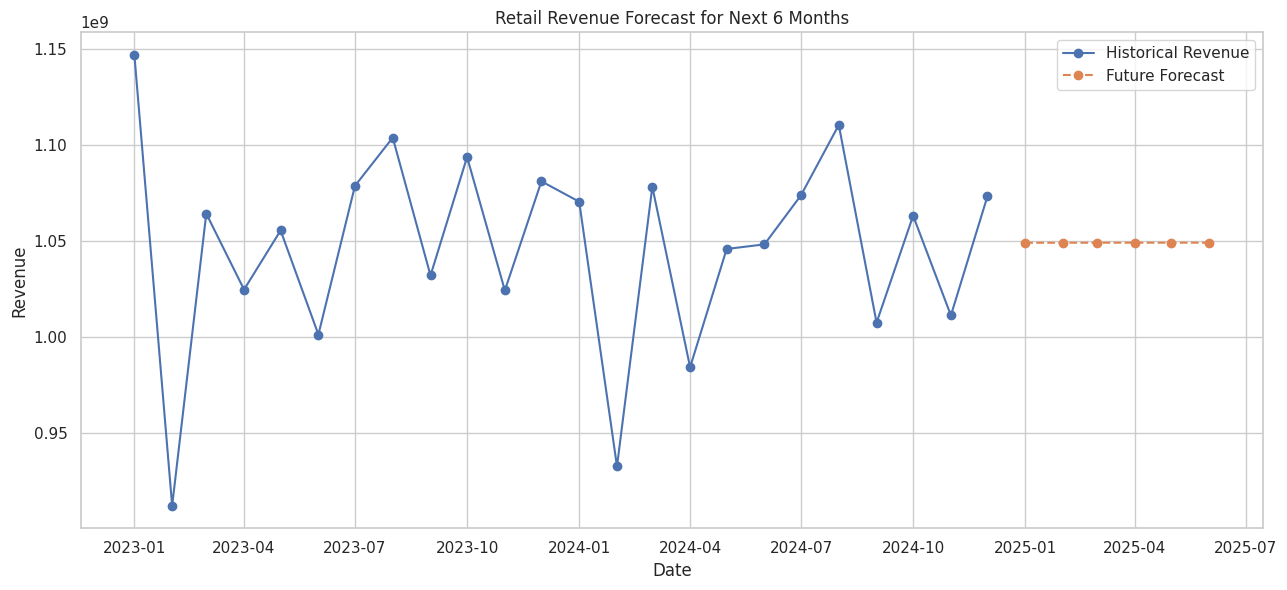

In [39]:
plt.figure(figsize=(13, 6))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    label="Historical Revenue",
    marker="o"
)
plt.plot(
    future_forecast.index,
    future_forecast.values,
    label="Future Forecast",
    marker="o",
    linestyle="--"
)
plt.title("Retail Revenue Forecast for Next 6 Months")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [40]:
store_data = df.groupby("Store_ID").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Units_Sold=("Units_Sold", "sum"),
    Average_Price=("Unit_Price", "mean"),
    Average_Rating=("Store_Rating", "mean"),
    Total_Transactions=("Product_ID", "count")
).reset_index()
print("Store Performance Data:")
display(store_data)

print("Number of stores:", len(store_data))

Store Performance Data:


,Store_ID,Total_Revenue,Total_Units_Sold,Average_Price,Average_Rating,Total_Transactions
0,STR_101,3.128283e+09,137476,25313.301076,4.253126,5455
1,STR_102,3.146458e+09,138776,24939.351023,4.251615,5572
2,STR_103,3.243379e+09,141230,25396.507822,4.253776,5614
3,STR_104,3.145558e+09,138896,25191.565550,4.257470,5582
4,STR_105,3.152386e+09,139742,25223.009630,4.240192,5628
5,STR_106,3.034981e+09,135185,24957.358477,4.245325,5423
6,STR_107,3.186874e+09,142446,24952.197683,4.244701,5633
7,STR_108,3.078556e+09,135250,25132.343024,4.256440,5450


Number of stores: 8


In [41]:
from sklearn.preprocessing import StandardScaler
features = [
    "Total_Revenue",
    "Total_Units_Sold",
    "Average_Price",
    "Average_Rating",
    "Total_Transactions"
]
scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    store_data[features]
)
print("Data standardization completed!")
print("Scaled data shape:", scaled_data.shape)

Data standardization completed!
Scaled data shape: (8, 5)


In [42]:
from sklearn.cluster import KMeans
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)
store_data["Cluster"] = kmeans.fit_predict(scaled_data)
print("K-Means clustering completed!")
display(store_data)

K-Means clustering completed!


,Store_ID,Total_Revenue,Total_Units_Sold,Average_Price,Average_Rating,Total_Transactions,Cluster
0,STR_101,3.128283e+09,137476,25313.301076,4.253126,5455,1
1,STR_102,3.146458e+09,138776,24939.351023,4.251615,5572,2
2,STR_103,3.243379e+09,141230,25396.507822,4.253776,5614,2
3,STR_104,3.145558e+09,138896,25191.565550,4.257470,5582,2
4,STR_105,3.152386e+09,139742,25223.009630,4.240192,5628,0
5,STR_106,3.034981e+09,135185,24957.358477,4.245325,5423,1
6,STR_107,3.186874e+09,142446,24952.197683,4.244701,5633,0
7,STR_108,3.078556e+09,135250,25132.343024,4.256440,5450,1


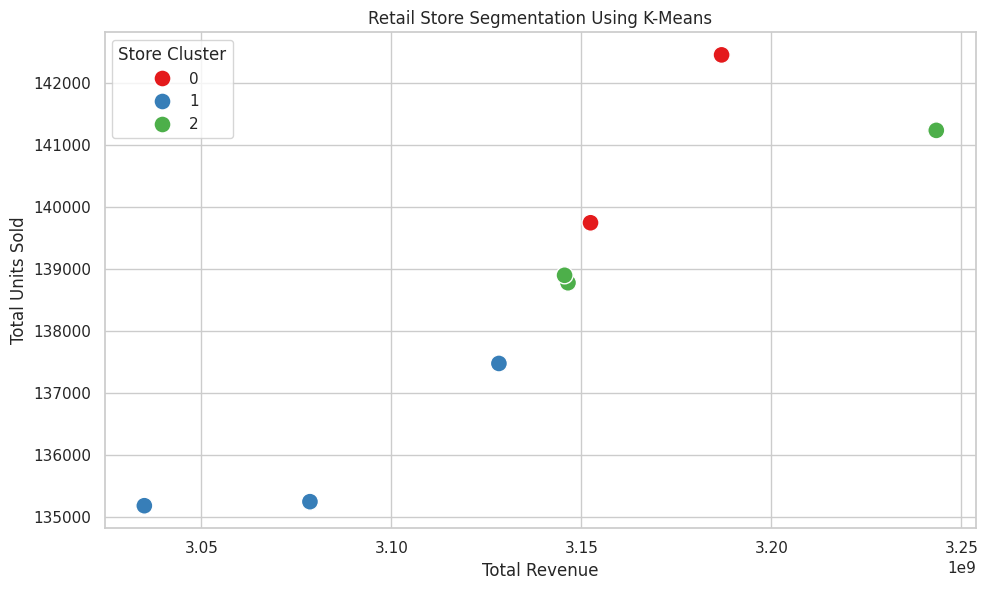

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=store_data,
    x="Total_Revenue",
    y="Total_Units_Sold",
    hue="Cluster",
    palette="Set1",
    s=150
)
plt.title("Retail Store Segmentation Using K-Means")
plt.xlabel("Total Revenue")
plt.ylabel("Total Units Sold")
plt.legend(title="Store Cluster")
plt.grid(True)
plt.tight_layout()
plt.show()

In [44]:
cluster_summary = store_data.groupby("Cluster").agg(
    Number_of_Stores=("Store_ID", "count"),
    Average_Revenue=("Total_Revenue", "mean"),
    Average_Units_Sold=("Total_Units_Sold", "mean"),
    Average_Rating=("Average_Rating", "mean")
).round(2)
display(cluster_summary)

,Number_of_Stores,Average_Revenue,Average_Units_Sold,Average_Rating
Cluster,,,,
0,2,3.169630e+09,141094.00,4.24
1,3,3.080607e+09,135970.33,4.25
2,3,3.178465e+09,139634.00,4.25


In [45]:
with pd.ExcelWriter(
    "Retail_Analytics_Results.xlsx",
    engine="openpyxl"
) as writer:
    df.to_excel(
        writer,
        sheet_name="Cleaned_Data",
        index=False
    )
    store_data.to_excel(
        writer,
        sheet_name="Store_Segmentation",
        index=False
    )
    cluster_summary.to_excel(
        writer,
        sheet_name="Cluster_Summary"
    )
    monthly_sales.to_frame(
        name="Revenue"
    ).to_excel(
        writer,
        sheet_name="Monthly_Revenue"
    )
    future_forecast.to_frame(
        name="Forecast_Revenue"
    ).to_excel(
        writer,
        sheet_name="Future_Forecast"
    )
print("Excel report generated successfully!")

Excel report generated successfully!


In [48]:
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
from IPython.display import display, HTML
total_revenue = df["Revenue"].sum()
total_sales = df["Total_Sales"].sum()
total_units = df["Units_Sold"].sum()
total_stores = df["Store_ID"].nunique()
fig = make_subplots(
    rows=3, cols=2,
    subplot_titles=(
        "Monthly Revenue Trend",
        "Revenue by Product Category",
        "Revenue by Store",
        "Revenue by Region",
        "Actual vs Predicted Revenue",
        "Future Revenue Forecast"
    ),
    specs=[
        [{"type": "scatter"}, {"type": "bar"}],
        [{"type": "bar"}, {"type": "pie"}],
        [{"type": "scatter"}, {"type": "scatter"}]
    ],
    vertical_spacing=0.13,
    horizontal_spacing=0.12
)
fig.add_trace(
    go.Scatter(
        x=monthly_sales.index,
        y=monthly_sales.values,
        mode="lines+markers",
        name="Monthly Revenue"
    ),
    row=1, col=1
)
category_revenue = df.groupby(
    "Product_Category"
)["Revenue"].sum().sort_values(ascending=False)
fig.add_trace(
    go.Bar(
        x=category_revenue.index,
        y=category_revenue.values,
        name="Category Revenue"
    ),
    row=1, col=2
)
store_revenue = df.groupby(
    "Store_ID"
)["Revenue"].sum().sort_values(ascending=False)

fig.add_trace(
    go.Bar(
        x=store_revenue.index.astype(str),
        y=store_revenue.values,
        name="Store Revenue"
    ),
    row=2, col=1
)
region_revenue = df.groupby(
    "Region"
)["Revenue"].sum()

fig.add_trace(
    go.Pie(
        labels=region_revenue.index,
        values=region_revenue.values,
        name="Region Revenue"
    ),
    row=2, col=2
)
fig.add_trace(
    go.Scatter(
        x=test.index,
        y=test.values,
        mode="lines+markers",
        name="Actual Revenue"
    ),
    row=3, col=1
)
fig.add_trace(
    go.Scatter(
        x=predictions.index,
        y=predictions.values,
        mode="lines+markers",
        name="Predicted Revenue"
    ),
    row=3, col=1
)
fig.add_trace(
    go.Scatter(
        x=future_forecast.index,
        y=future_forecast.values,
        mode="lines+markers",
        name="Future Forecast"
    ),
    row=3, col=2
)
fig.update_layout(
    title="RETAIL ANALYTICS & SALES FORECASTING DASHBOARD",
    height=1100,
    template="plotly_white",
    showlegend=True
)
fig.show()
display(HTML(f"""
<div style="display:flex;flex-wrap:wrap;gap:15px;font-family:Arial;">
  <div style="background:#e6f4f1;padding:20px;border-radius:12px;min-width:180px;">
    <h4>Total Revenue</h4><h2>{total_revenue:,.2f}</h2>
  </div>
  <div style="background:#eaf1fb;padding:20px;border-radius:12px;min-width:180px;">
    <h4>Total Sales</h4><h2>{total_sales:,.2f}</h2>
  </div>
  <div style="background:#fff3df;padding:20px;border-radius:12px;min-width:180px;">
    <h4>Units Sold</h4><h2>{total_units:,.0f}</h2>
  </div>
  <div style="background:#f2eafa;padding:20px;border-radius:12px;min-width:180px;">
    <h4>Total Stores</h4><h2>{total_stores}</h2>
  </div>
</div>
"""))

In [50]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
mae = mean_absolute_error(test, predictions)
rmse = np.sqrt(
    mean_squared_error(test, predictions)
)
mape = np.mean(
    np.abs((test - predictions) / test.replace(0, np.nan))
) * 100
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

MAE: 34800410.05
RMSE: 37831323.4
MAPE: 3.28 %


In [51]:
print("STORE SEGMENTATION RESULTS")
display(store_data)
print("\nCLUSTER SUMMARY")
display(cluster_summary)

STORE SEGMENTATION RESULTS


,Store_ID,Total_Revenue,Total_Units_Sold,Average_Price,Average_Rating,Total_Transactions,Cluster
0,STR_101,3.128283e+09,137476,25313.301076,4.253126,5455,1
1,STR_102,3.146458e+09,138776,24939.351023,4.251615,5572,2
2,STR_103,3.243379e+09,141230,25396.507822,4.253776,5614,2
3,STR_104,3.145558e+09,138896,25191.565550,4.257470,5582,2
4,STR_105,3.152386e+09,139742,25223.009630,4.240192,5628,0
5,STR_106,3.034981e+09,135185,24957.358477,4.245325,5423,1
6,STR_107,3.186874e+09,142446,24952.197683,4.244701,5633,0
7,STR_108,3.078556e+09,135250,25132.343024,4.256440,5450,1



CLUSTER SUMMARY


,Number_of_Stores,Average_Revenue,Average_Units_Sold,Average_Rating
Cluster,,,,
0,2,3.169630e+09,141094.00,4.24
1,3,3.080607e+09,135970.33,4.25
2,3,3.178465e+09,139634.00,4.25
